# Stage 4 — Honest evaluation

Crack segmentation and measurement project. Explanations: see the study guide.

In [1]:
# Cell 1 — Install, import and settings
%pip install -q segmentation-models-pytorch

from pathlib import Path
import json
import re

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

DATA_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PAD = 416
BORDER = (PAD - 400) // 2
TOLERANCE_PX = 2          # boundary tolerance for thin-crack scoring
MIN_CRACK_PX = 100        # an image "contains a crack" if at least this many pixels are crack
print("device:", DEVICE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
device: cuda


In [2]:
# Cell 2 — Index and splits (same rules as Stages 1 and 3)
TRAIN_SOURCES = ["CRACK500", "Rissbilder", "Noncrack", "Volker", "GAPS384", "Misc"]
UNSEEN_SOURCES = ["DeepCrack", "CFD", "Ceramic"]
EXCLUDED_SOURCES = ["CrackTree200"]
SPLIT_FRACTIONS = {"train": 0.8, "val": 0.1, "test_seen": 0.1}
SPLIT_SEED = 0

folders = {p.name: p for p in DATA_ROOT.rglob("*")
           if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}
SOURCE_RULES = [
    ("CRACK500", "CRACK500"), ("Rissbilder", "Rissbilder"), ("noncrack", "Noncrack"),
    ("DeepCrack", "DeepCrack"), ("Volker", "Volker"), ("GAPS384", "GAPS384"),
    ("cracktree200", "CrackTree200"), ("CFD", "CFD"), ("Ceramic", "Ceramic"),
]

def source_of(name):
    for prefix, source in SOURCE_RULES:
        if name.startswith(prefix):
            return source
    return "Misc"

def parent_of(name, source):
    stem = name.rsplit(".", 1)[0]
    parts = stem.split("_")
    if source in ("CRACK500", "GAPS384"):
        return "_".join(parts[1:3])
    if source == "Rissbilder":
        return parts[3]
    if source == "Volker":
        return parts[1]
    if source == "Noncrack":
        return "_".join(parts[:5])
    if source == "DeepCrack":
        return stem.split("_", 1)[1].split("-")[0]
    if source == "Misc":
        return "_".join(parts[:2])
    return stem

def assign_splits(frame, fractions, seed):
    rng = np.random.default_rng(seed)
    split_of_parent = {}
    for source in TRAIN_SOURCES:
        parents = np.array(sorted(frame.loc[frame["source"] == source, "parent"].unique()))
        rng.shuffle(parents)
        n_train = int(round(fractions["train"] * len(parents)))
        n_val = int(round(fractions["val"] * len(parents)))
        for k, parent in enumerate(parents):
            split_of_parent[parent] = ("train" if k < n_train else
                                       "val" if k < n_train + n_val else "test_seen")
    split = frame["parent"].map(split_of_parent)
    split[frame["source"].isin(UNSEEN_SOURCES)] = "test_unseen"
    split[frame["source"].isin(EXCLUDED_SOURCES)] = "excluded"
    return split

rows = []
for folder in ("Images", "Images-2"):
    for img_path in sorted(folders[folder].glob("*.png")):
        source = source_of(img_path.name)
        rows.append({"name": img_path.name, "source": source,
                     "parent": f"{source}/{parent_of(img_path.name, source)}",
                     "image": str(img_path), "mask": str(folders["Masks"] / img_path.name)})
df = pd.DataFrame(rows)
df["split"] = assign_splits(df, SPLIT_FRACTIONS, SPLIT_SEED)
print(df["split"].value_counts())

split
train          6550
test_seen       933
val             840
test_unseen     661
excluded        175
Name: count, dtype: int64


In [3]:
# Cell 3 — Find the trained models
checkpoints = sorted(DATA_ROOT.rglob("best_*.pth"))
for c in checkpoints:
    print(c)
assert checkpoints, "Attach the Stage 3 notebook output: Add Input -> Your Work -> stage3_train"

def seed_of(path):
    m = re.search(r"seed(\d+)", path.name)
    return int(m.group(1)) if m else -1

def load_model(path):
    model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=1)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    return model.to(DEVICE).eval()

/kaggle/input/notebooks/richardolanite/stage3-training/best_resnet34_seed0.pth


In [4]:
# Cell 4 — Predict every evaluation image once
eval_tf = A.Compose([
    A.PadIfNeeded(min_height=PAD, min_width=PAD, border_mode=cv2.BORDER_REFLECT_101),
    A.Normalize(),
    ToTensorV2(),
])

def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

class ImageOnly(Dataset):
    def __init__(self, frame):
        self.paths = frame["image"].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = np.array(Image.open(self.paths[i]).convert("RGB"))
        return eval_tf(image=image)["image"]

@torch.no_grad()
def predict(model, frame, batch_size=16):
    loader = DataLoader(ImageOnly(frame), batch_size=batch_size, num_workers=2)
    probs = []
    for images in tqdm(loader, leave=False):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(images.to(DEVICE))
        p = torch.sigmoid(logits.float())[:, 0, BORDER:-BORDER, BORDER:-BORDER]
        probs.extend((p * 255).round().byte().cpu().numpy())    # store as 0-255 to save memory
    return probs

eval_df = df[df["split"].isin(["val", "test_seen", "test_unseen"])].reset_index(drop=True)
labels = [load_mask(p) for p in tqdm(eval_df["mask"], desc="labels")]

probs_by_seed = {}
for path in checkpoints:
    model = load_model(path)
    probs_by_seed[seed_of(path)] = predict(model, eval_df)
    print(f"seed {seed_of(path)}: predicted {len(eval_df)} images")

labels:   0%|          | 0/2434 [00:00<?, ?it/s]

  0%|          | 0/153 [00:00<?, ?it/s]

seed 0: predicted 2434 images


In [5]:
# Cell 5 — Per-image counts at a given threshold
disk = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * TOLERANCE_PX + 1, 2 * TOLERANCE_PX + 1))

def image_counts(prob, label, threshold):
    pred = prob >= threshold * 255
    tp = int((pred & label).sum())
    fp = int((pred & ~label).sum())
    fn = int((~pred & label).sum())
    near_label = cv2.dilate(label.astype(np.uint8), disk).astype(bool)
    near_pred = cv2.dilate(pred.astype(np.uint8), disk).astype(bool)
    return {"tp": tp, "fp": fp, "fn": fn,
            "pred_px": int(pred.sum()), "label_px": int(label.sum()),
            "pred_near_label": int((pred & near_label).sum()),     # tolerant precision numerator
            "label_near_pred": int((label & near_pred).sum())}     # tolerant recall numerator

def counts_table(seed, threshold, mask=None):
    idx = np.arange(len(eval_df)) if mask is None else np.flatnonzero(mask)
    rows = [image_counts(probs_by_seed[seed][i], labels[i], threshold) for i in idx]
    out = pd.DataFrame(rows, index=idx, columns=["tp", "fp", "fn", "pred_px", "label_px",
                                                 "pred_near_label", "label_near_pred"])
    return eval_df.loc[idx, ["name", "source", "parent", "split"]].join(out)

def summarise(c):
    tp, fp, fn = c["tp"].sum(), c["fp"].sum(), c["fn"].sum()
    tol_p = c["pred_near_label"].sum() / max(c["pred_px"].sum(), 1)
    tol_r = c["label_near_pred"].sum() / max(c["label_px"].sum(), 1)
    return pd.Series({
        "images": len(c),
        "Dice": 2 * tp / (2 * tp + fp + fn),
        "IoU": tp / (tp + fp + fn),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        f"F1 (±{TOLERANCE_PX} px)": 2 * tol_p * tol_r / max(tol_p + tol_r, 1e-9),
    })

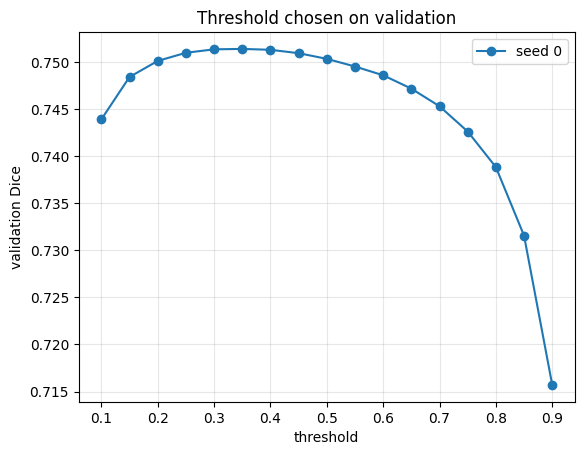

chosen thresholds: {0: 0.35}


In [6]:
# Cell 6 — Choose the threshold on validation only
thresholds = np.round(np.arange(0.1, 0.91, 0.05), 2)
is_val = (eval_df["split"] == "val").to_numpy()
best_threshold, sweep_rows = {}, []
for seed in probs_by_seed:
    for t in thresholds:
        s = summarise(counts_table(seed, t, is_val))
        sweep_rows.append({"seed": seed, "threshold": t, "val_Dice": s["Dice"]})
sweep = pd.DataFrame(sweep_rows)
for seed, g in sweep.groupby("seed"):
    best_threshold[seed] = float(g.loc[g["val_Dice"].idxmax(), "threshold"])
    plt.plot(g["threshold"], g["val_Dice"], marker="o", label=f"seed {seed}")
plt.xlabel("threshold")
plt.ylabel("validation Dice")
plt.title("Threshold chosen on validation")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print("chosen thresholds:", best_threshold)

In [7]:
# Cell 7 — Test results: seen vs unseen sources
results, per_image = [], {}
for seed, t in best_threshold.items():
    c = counts_table(seed, t)
    per_image[seed] = c
    for split in ["val", "test_seen", "test_unseen"]:
        results.append({"seed": seed, "group": split, **summarise(c[c["split"] == split])})
    for source in UNSEEN_SOURCES:
        results.append({"seed": seed, "group": f"unseen: {source}", **summarise(c[c["source"] == source])})
    for source in TRAIN_SOURCES:
        sel = (c["split"] == "test_seen") & (c["source"] == source)
        results.append({"seed": seed, "group": f"seen: {source}", **summarise(c[sel])})
results = pd.DataFrame(results)
metric_cols = ["Dice", "IoU", "precision", "recall", f"F1 (±{TOLERANCE_PX} px)"]
table = results.groupby("group", sort=False).agg(
    images=("images", "first"), **{m: (m, "mean") for m in metric_cols})
if len(best_threshold) > 1:
    table["Dice sd"] = results.groupby("group", sort=False)["Dice"].std()
print(table.round(3).to_string())

                   images   Dice    IoU  precision  recall  F1 (±2 px)
group                                                                 
val                 840.0  0.751  0.602      0.716   0.791       0.852
test_seen           933.0  0.742  0.590      0.706   0.783       0.845
test_unseen         661.0  0.704  0.543      0.623   0.808       0.859
unseen: DeepCrack   443.0  0.771  0.627      0.687   0.877       0.919
unseen: CFD         118.0  0.602  0.431      0.492   0.775       0.866
unseen: Ceramic     100.0  0.290  0.170      0.267   0.318       0.377
seen: CRACK500      348.0  0.772  0.629      0.749   0.797       0.846
seen: Rissbilder    319.0  0.599  0.428      0.510   0.727       0.828
seen: Noncrack      156.0  0.000  0.000      0.000   0.000       0.000
seen: Volker         39.0  0.732  0.577      0.810   0.667       0.894
seen: GAPS384        40.0  0.538  0.368      0.502   0.579       0.725
seen: Misc           31.0  0.875  0.778      0.865   0.885       0.938


In [8]:
# Cell 8 — Uncertainty: 95% bootstrap intervals over photos
def bootstrap_dice(c, n_boot=1000, seed=0):
    g = c.groupby("parent")[["tp", "fp", "fn"]].sum().to_numpy()   # resample whole photos
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(n_boot):
        s = g[rng.integers(0, len(g), len(g))].sum(axis=0)
        stats.append(2 * s[0] / (2 * s[0] + s[1] + s[2]))
    return np.percentile(stats, [2.5, 97.5])

first_seed = sorted(per_image)[0]
c = per_image[first_seed]
for group, sel in [("test_seen", c["split"] == "test_seen"),
                   ("test_unseen", c["split"] == "test_unseen"),
                   *[(f"unseen: {s}", c["source"] == s) for s in UNSEEN_SOURCES]]:
    lo, hi = bootstrap_dice(c[sel])
    point = summarise(c[sel])["Dice"]
    print(f"{group:20s} Dice {point:.3f}  95% CI {lo:.3f}-{hi:.3f}")

test_seen            Dice 0.742  95% CI 0.712-0.772
test_unseen          Dice 0.704  95% CI 0.664-0.738
unseen: DeepCrack    Dice 0.771  95% CI 0.739-0.795
unseen: CFD          Dice 0.602  95% CI 0.581-0.621
unseen: Ceramic      Dice 0.290  95% CI 0.235-0.350


In [9]:
# Cell 9 — Image-level view: found cracks and false alarms
c = per_image[first_seed].copy()
c["has_crack"] = c["label_px"] >= MIN_CRACK_PX
c["flagged"] = c["pred_px"] >= MIN_CRACK_PX
summary = c.groupby("source").apply(lambda g: pd.Series({
    "crack images": int(g["has_crack"].sum()),
    "found (%)": 100 * g.loc[g["has_crack"], "flagged"].mean() if g["has_crack"].any() else np.nan,
    "crack-free images": int((~g["has_crack"]).sum()),
    "false alarms (%)": 100 * g.loc[~g["has_crack"], "flagged"].mean() if (~g["has_crack"]).any() else np.nan,
}), include_groups=False)
print(summary.round(1).to_string())

            crack images  found (%)  crack-free images  false alarms (%)
source                                                                  
CFD                118.0       99.2                0.0               NaN
CRACK500           640.0       98.6                0.0               NaN
Ceramic            100.0       81.0                0.0               NaN
DeepCrack          443.0       99.1                0.0               NaN
GAPS384             78.0       98.7                0.0               NaN
Misc                59.0       98.3                0.0               NaN
Noncrack             2.0       50.0              386.0               4.9
Rissbilder         521.0       98.3                4.0              25.0
Volker              83.0      100.0                0.0               NaN


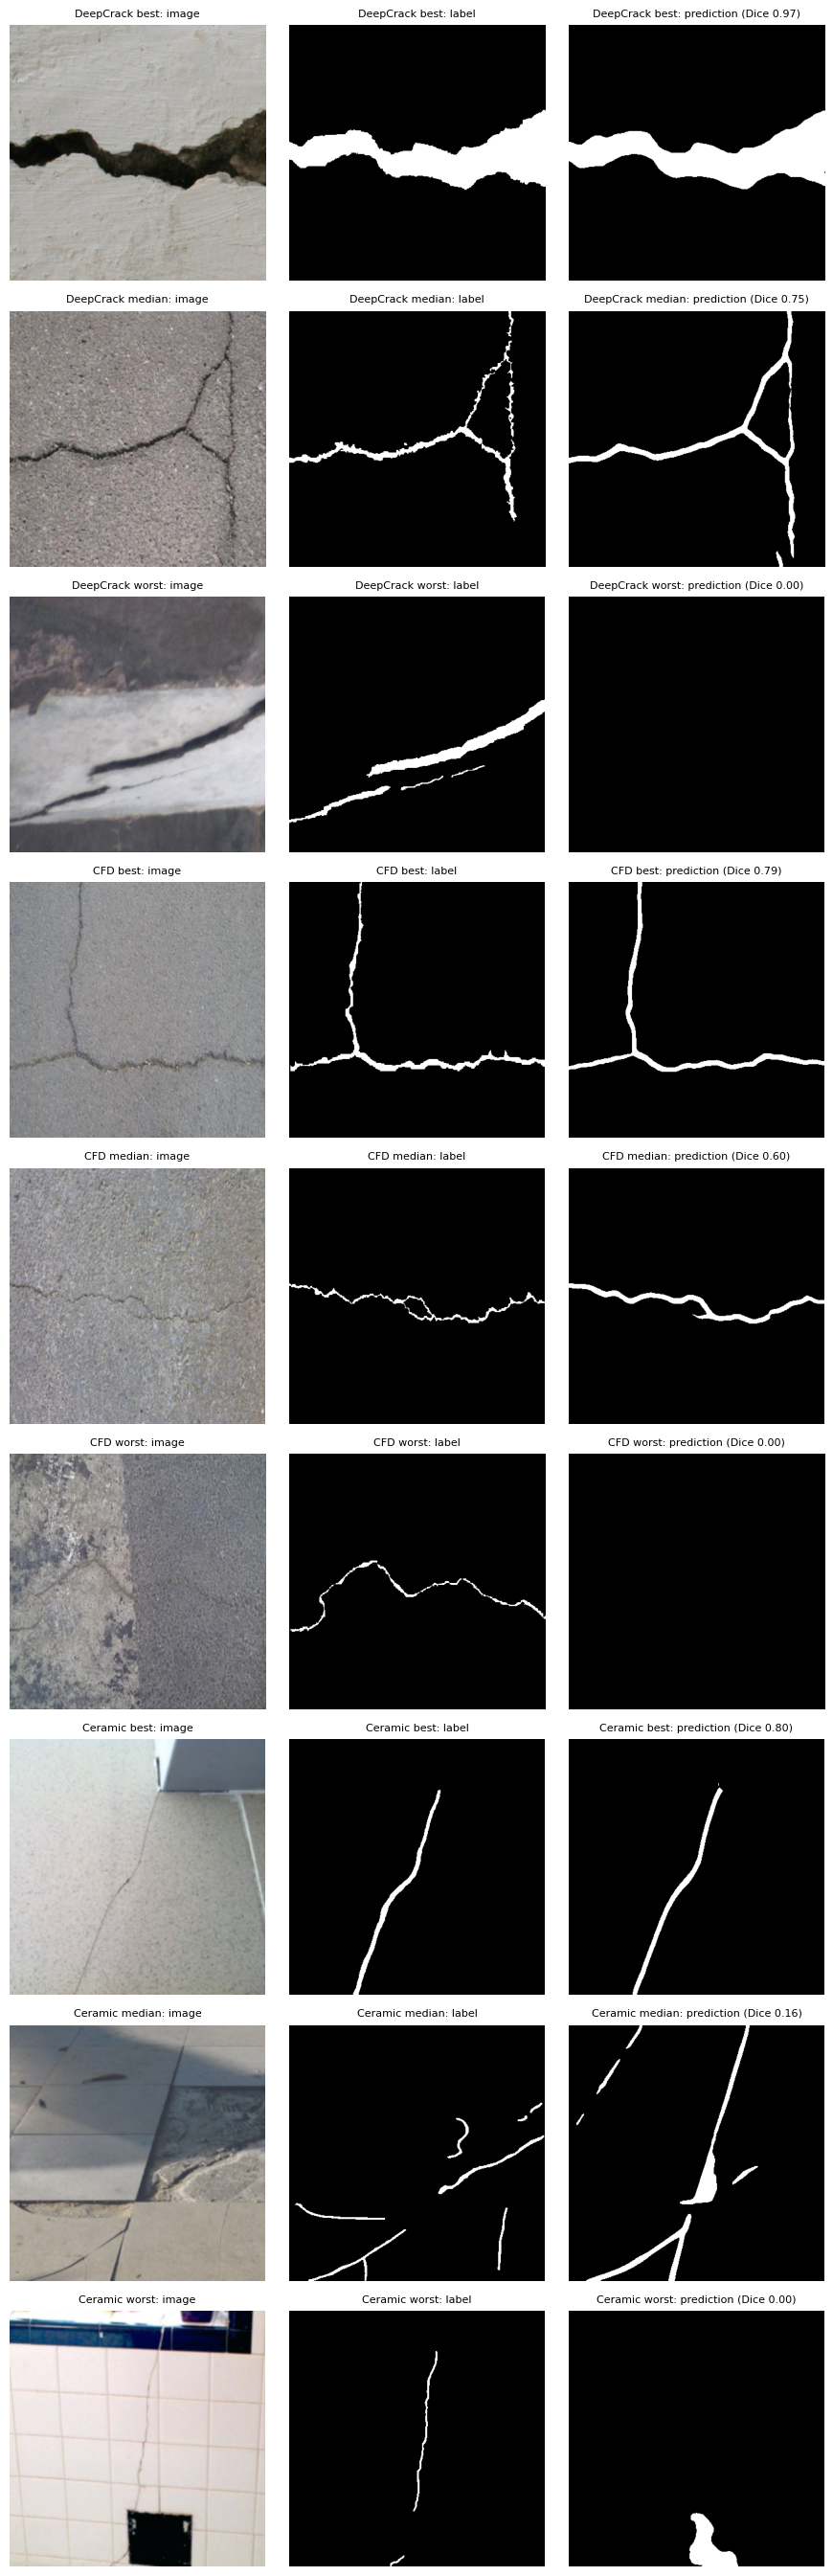

In [10]:
# Cell 10 — Best, typical and worst unseen images
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
c = per_image[first_seed]
c = c.assign(dice=2 * c["tp"] / (2 * c["tp"] + c["fp"] + c["fn"]).clip(lower=1))
fig, axes = plt.subplots(len(UNSEEN_SOURCES) * 3, 3, figsize=(9, 9 * len(UNSEEN_SOURCES)))
r = 0
for source in UNSEEN_SOURCES:
    g = c[(c["source"] == source) & (c["label_px"] >= MIN_CRACK_PX)].sort_values("dice")
    for tag, i in [("best", g.index[-1]), ("median", g.index[len(g) // 2]), ("worst", g.index[0])]:
        img = np.array(Image.open(eval_df.loc[i, "image"]).convert("RGB"))
        pred = probs_by_seed[first_seed][i] >= best_threshold[first_seed] * 255
        for ax, (title, shown) in zip(axes[r], [("image", img), ("label", labels[i]), ("prediction", pred)]):
            ax.imshow(shown, cmap="gray")
            ax.set_title(f"{source} {tag}: {title}" + (f" (Dice {c.loc[i, 'dice']:.2f})" if title == "prediction" else ""),
                         fontsize=8)
            ax.axis("off")
        r += 1
plt.tight_layout()
plt.savefig(OUT_DIR / "unseen_examples.png", dpi=90)
plt.show()

In [11]:
# Cell 11 — Save results
table.round(4).to_csv(OUT_DIR / "results_table.csv")
results.to_csv(OUT_DIR / "results_by_seed.csv", index=False)
sweep.to_csv(OUT_DIR / "threshold_sweep.csv", index=False)
pd.concat(per_image, names=["seed"]).to_csv(OUT_DIR / "per_image_counts.csv")
with open(OUT_DIR / "thresholds.json", "w") as f:
    json.dump(best_threshold, f)
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))

saved: ['__notebook__.ipynb', 'per_image_counts.csv', 'results_by_seed.csv', 'results_table.csv', 'threshold_sweep.csv', 'thresholds.json', 'unseen_examples.png']
